# Stage 4: CyTOF analysis

Reload the Stage 3 labeled, balanced, z-scored table. This stage preserves the source notebook's marker order (including duplicate CD109), pooled and per-experiment comparisons, every treated/untreated sample pair, subtype proportions, and both distinct subtype KDE overlays. The source pairwise-export cell was interrupted, so a fresh run is needed to establish complete output coverage.

In [1]:
# ruff: noqa: E402, E501
from pathlib import Path
import sys

# Support launching Jupyter from either the checkout root or its notebooks folder.
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "app").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
# Prefer this checkout over another installed copy or worktree of app.
sys.path.insert(0, str(PROJECT_ROOT))
import app  # noqa: E402

# Fail early if Python resolved app from outside this checkout.
if Path(app.__file__).resolve().parent != PROJECT_ROOT / "app":
    raise RuntimeError("app was imported from outside the intended checkout")

In [2]:
from app.dotenv import OUTPUT_ROOT  # noqa: E402
# from app.preprocessing import add_cell_uid  # noqa: E402

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from app.analysis import plot_kde_comparison, plot_treatment_comparisons

In [3]:
INPUT_DIR = (
    OUTPUT_ROOT
    / "5. GFP_high_balanced_per_experiment, & Z_scored"
    / "7. GFP_high_balanced_per_experiment_ZSCORED"
)


KDE_OUT = OUTPUT_ROOT / "8. KDE_analysis" 
SEPARATING_MARKERS = [
    "TSPAN8",
    "GATA6",
    "GAL4",
    "KRT5",
    "KRT17",
    "CD44",
    "CD109",
    "Vimentin",
    "EpCAM",
    "CD24",
    "E-cadherin",
    "KI67",
    "pRb",
    "CD109",
]

In [4]:
if not INPUT_DIR.is_dir():
    raise FileNotFoundError(f"Data folder not found: {INPUT_DIR}")
df = pd.read_csv(INPUT_DIR / "all_GFP_high_BALANCED_ZSCORED.csv", low_memory=False)

# df = add_cell_uid(df)
missing_markers = [marker for marker in SEPARATING_MARKERS if marker not in df.columns]
if missing_markers:
    raise ValueError(f"Missing selected marker columns: {missing_markers}")
print(f"Selected markers: {SEPARATING_MARKERS}")
display(df[["experiment", "sample_name", "condition", "labels", "leiden_cluster","cell_uid"]].head())

Selected markers: ['TSPAN8', 'GATA6', 'GAL4', 'KRT5', 'KRT17', 'CD44', 'CD109', 'Vimentin', 'EpCAM', 'CD24', 'E-cadherin', 'KI67', 'pRb', 'CD109']


,experiment,sample_name,condition,labels,leiden_cluster,cell_uid
0,batch2,batch2_1473_gem,treated,basal,0.0,batch2_1473_gem_5825
1,batch2,batch2_1473_gem,treated,basal,2.0,batch2_1473_gem_13125
2,batch2,batch2_1473_gem,treated,basal,5.0,batch2_1473_gem_8449
3,batch2,batch2_1473_gem,treated,classical,1.0,batch2_1473_gem_5185
4,batch2,batch2_1473_gem,treated,classical,1.0,batch2_1473_gem_11581


## Expression distributions and biological comparisons

Generate pooled comparisons, per-experiment comparisons, and every treated/untreated sample pair in separate cells. Each call saves the five source KDE comparisons and subtype proportions.


## 1. Subtype KDE overlays

These are separate source products: treated cells overlaid with treated basal and classical cells, then treated and untreated distributions overlaid by subtype.

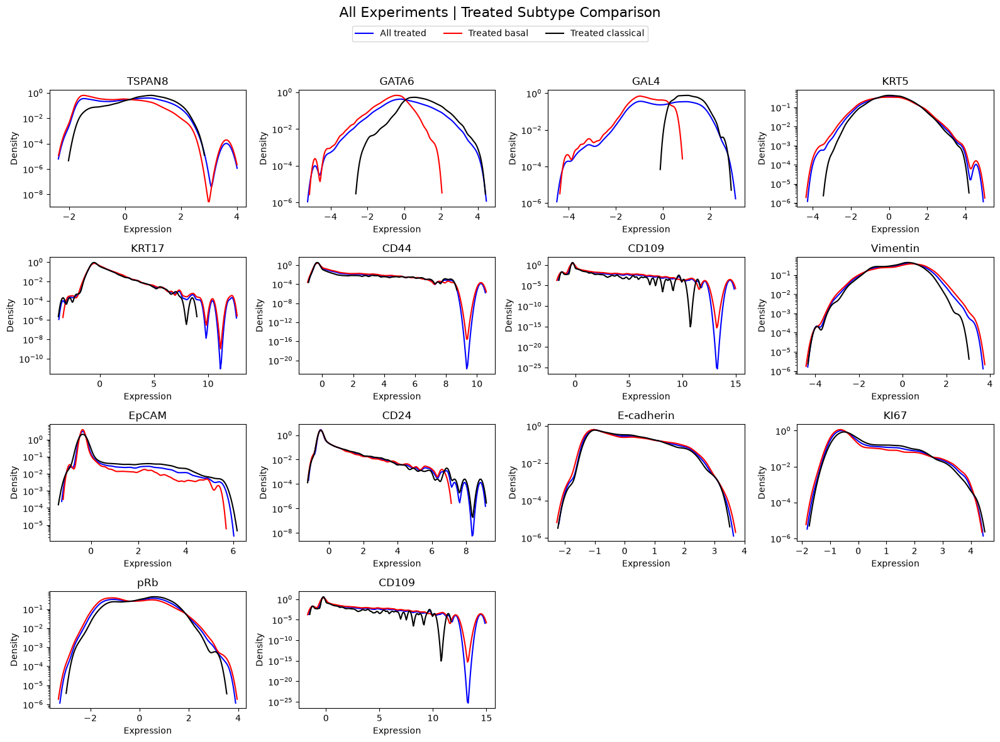

,marker,condition,expression,density
0,TSPAN8,All treated,-2.384535,0.000006
1,TSPAN8,All treated,-2.352393,0.000013
2,TSPAN8,All treated,-2.320252,0.000026
3,TSPAN8,All treated,-2.288110,0.000050
4,TSPAN8,All treated,-2.255968,0.000090
...,...,...,...,...
8395,CD109,Treated classical,11.421394,0.000336
8396,CD109,Treated classical,11.487751,0.000267
8397,CD109,Treated classical,11.554107,0.000117
8398,CD109,Treated classical,11.620463,0.000028


In [5]:
# =========================
# 1. SUBTYPE KDE OVERLAYS
# =========================

# Compare all treated cells with treated basal and classical cells.
treated = df[df["condition"] == "treated"]
treated_groups = [
    treated,
    treated[treated["labels"] == "basal"],
    treated[treated["labels"] == "classical"],
]
plot_kde_comparison(
    data=treated_groups,
    comparisons=[
        (0, "All treated", "blue"),
        (1, "Treated basal", "red"),
        (2, "Treated classical", "black"),
    ],
    cols=SEPARATING_MARKERS,
    title="All Experiments | Treated Subtype Comparison",
    fname=KDE_OUT / "all_experiments" / "treated_subtypes.png",
    figsize=(16, 12),
)

[(0, 'Treated All', 'blue', '-'), (1, 'Untreated All', 'blue', '--'), (2, 'Treated Basal', 'red', '-'), (3, 'Untreated Basal', 'red', '--'), (4, 'Treated Classical', 'black', '-'), (5, 'Untreated Classical', 'black', '--')]


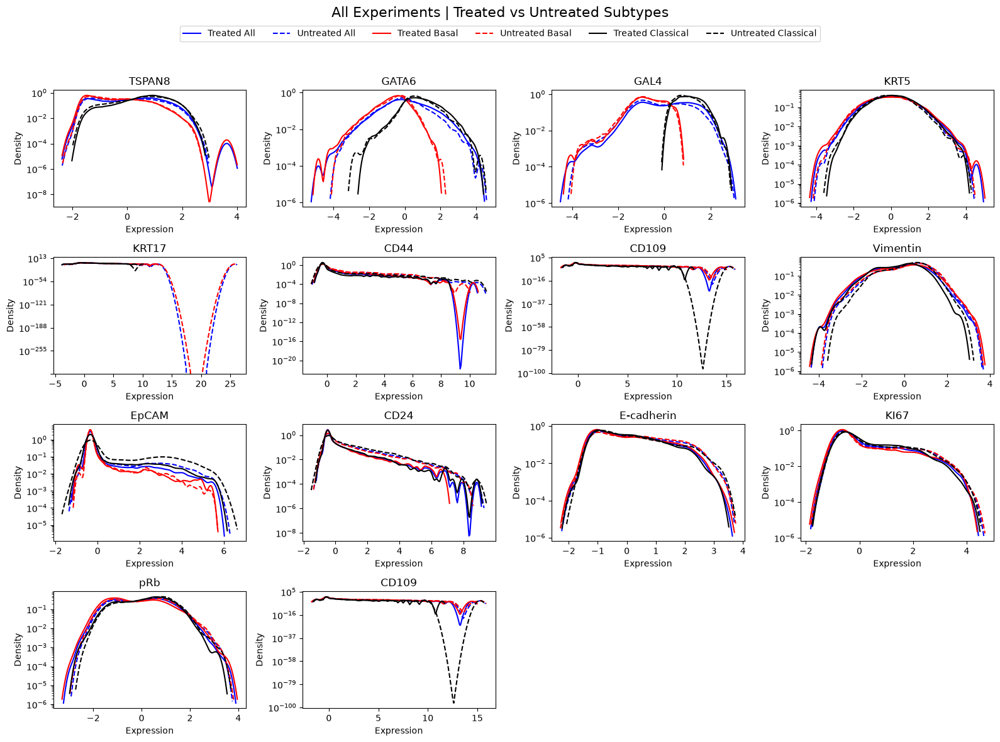

In [6]:
# =========================
# 2. TREATED VS UNTREATED SUBTYPE OVERLAYS
# =========================
subtype_output = KDE_OUT / "all_experiments" / "treated_vs_untreated_subtypes.png"


# Compare treated and untreated cells for all cells, basal, and classical groups.
subtypes = [(None, "blue"), ("basal", "red"), ("classical", "black")]
conditions = [("treated", "-"), ("untreated", "--")]
# Keep each subtype's treated group next to its untreated group, matching the comparison order below.
subtype_groups = []
for label, _ in subtypes:
    for condition, _ in conditions:
        # The All subtype includes every cell in the condition; named subtypes also filter by label.
        if label is not None:
            group = df[(df["condition"] == condition) & (df["labels"] == label)]
        else:
            group = df[df["condition"] == condition]
        # plot_kde_comparison selects each DataFrame by its position in this list.
        subtype_groups.append(group)
subtype_comparisons = [
    (index, f"{condition.title()} {('All' if label is None else label.title())}", color, linestyle)
    for index, ((label, color), (condition, linestyle)) in enumerate(
        (subtype, condition) for subtype in subtypes for condition in conditions
    )
]
print(subtype_comparisons)
subtype_density = plot_kde_comparison(
    data=subtype_groups,
    comparisons=subtype_comparisons,
    cols=SEPARATING_MARKERS,
    title="All Experiments | Treated vs Untreated Subtypes",
    fname=subtype_output,
    figsize=(16, 12),
)

## 2. All experiments

This cell compares all treated cells with all untreated cells pooled across experiments. `plot_treatment_comparisons` saves five KDE comparisons (all cells, basal, classical, and both cross-subtype pairs), plus subtype proportions, under `KDE_OUT / "all_experiments"`. The final lines load and preview the pooled proportions table.


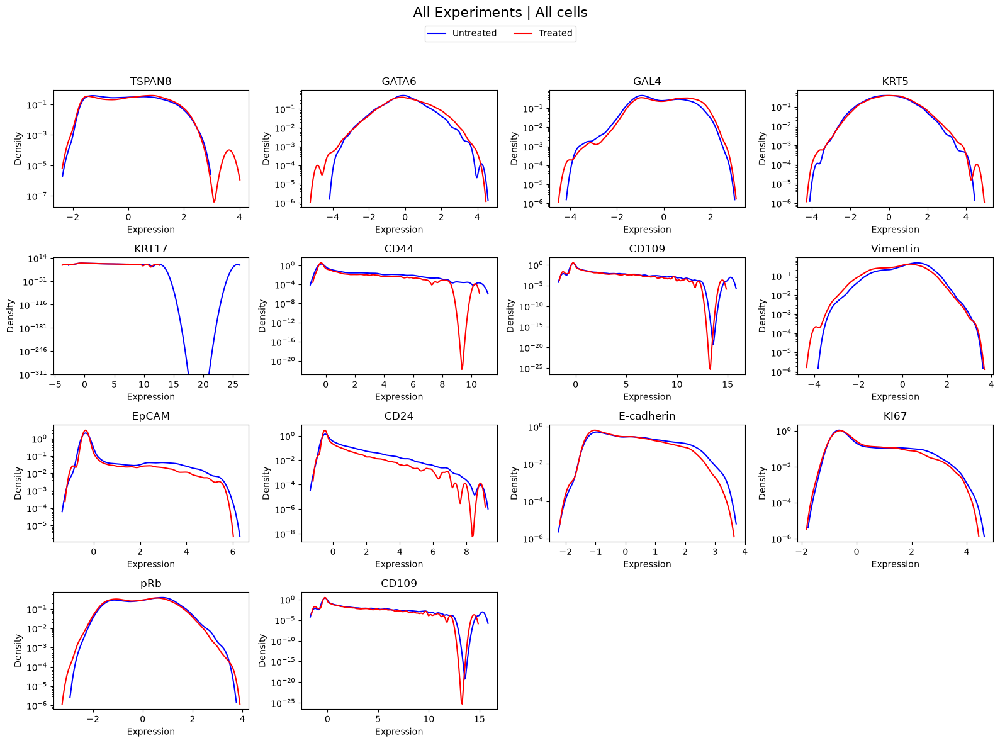

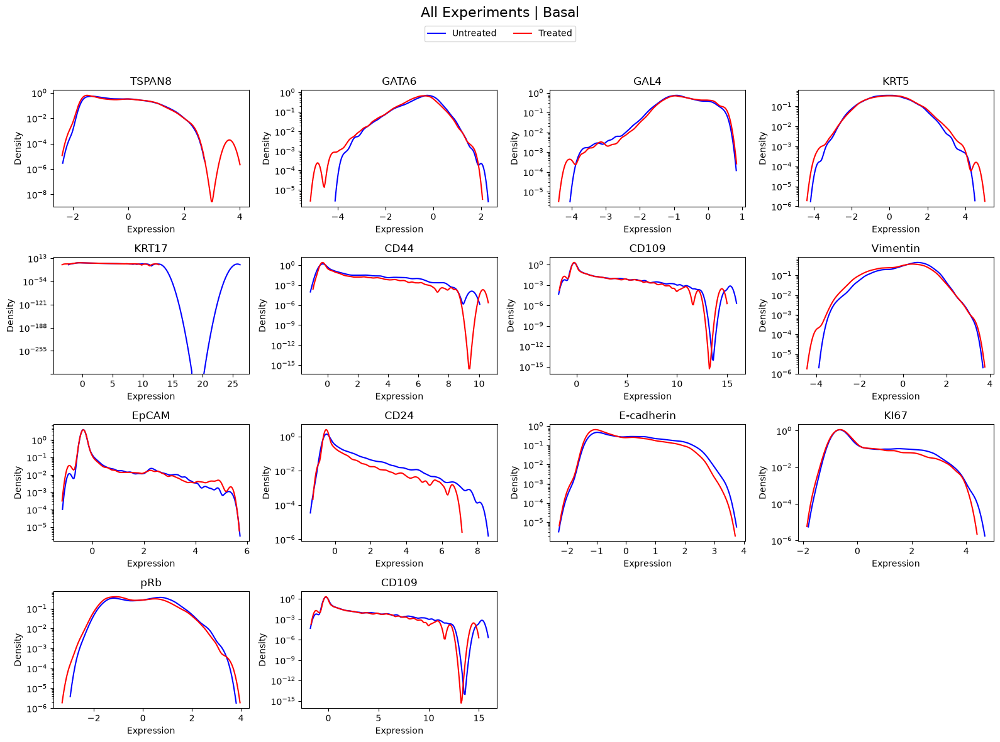

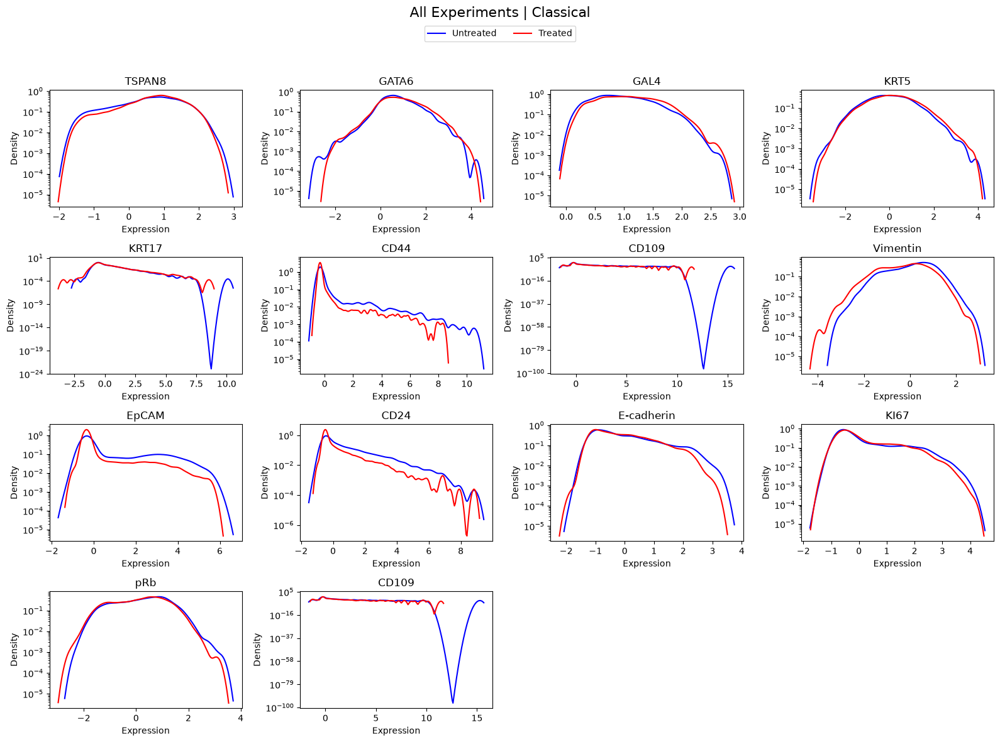

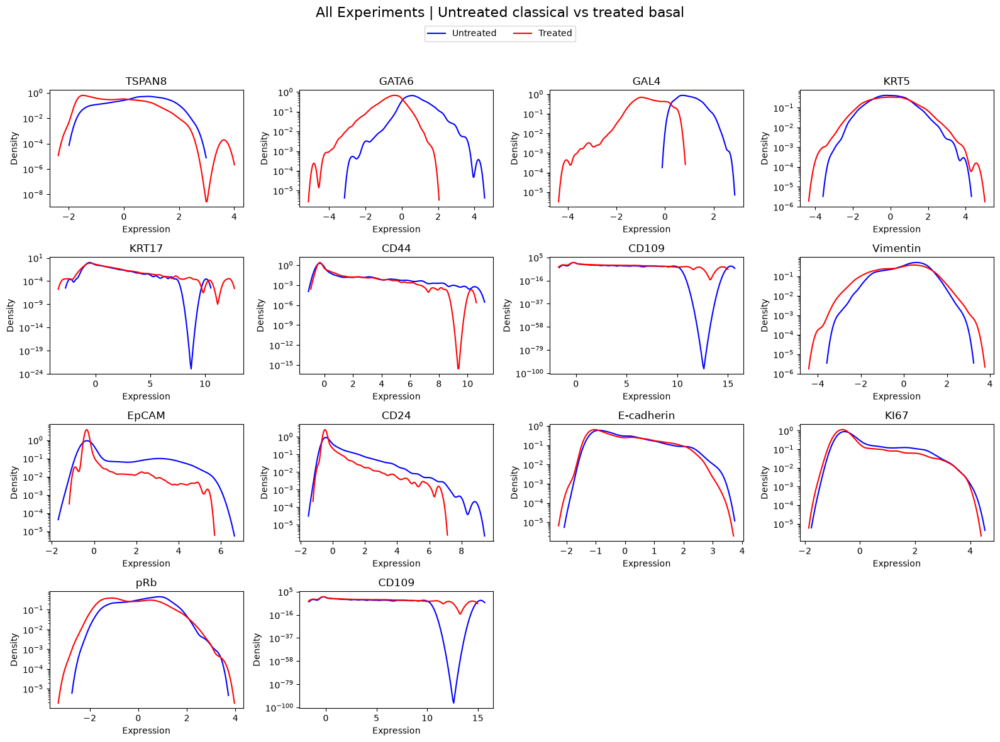

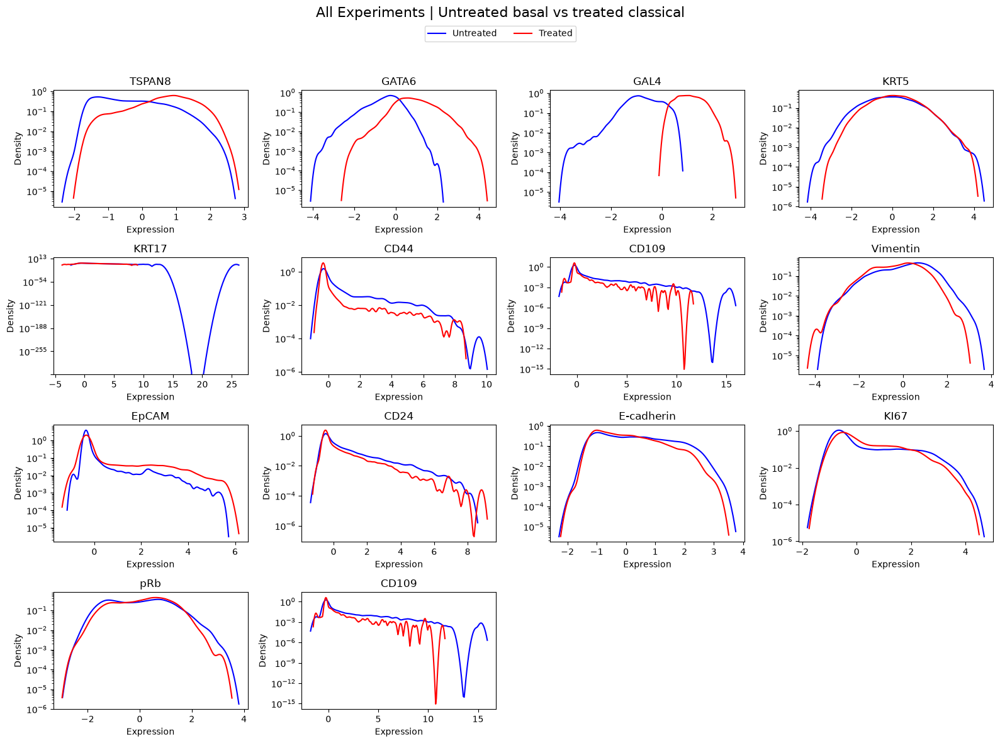

/Users/yishai/Desktop/epigenetics_field_theory/app/analysis/kde.py:208: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(


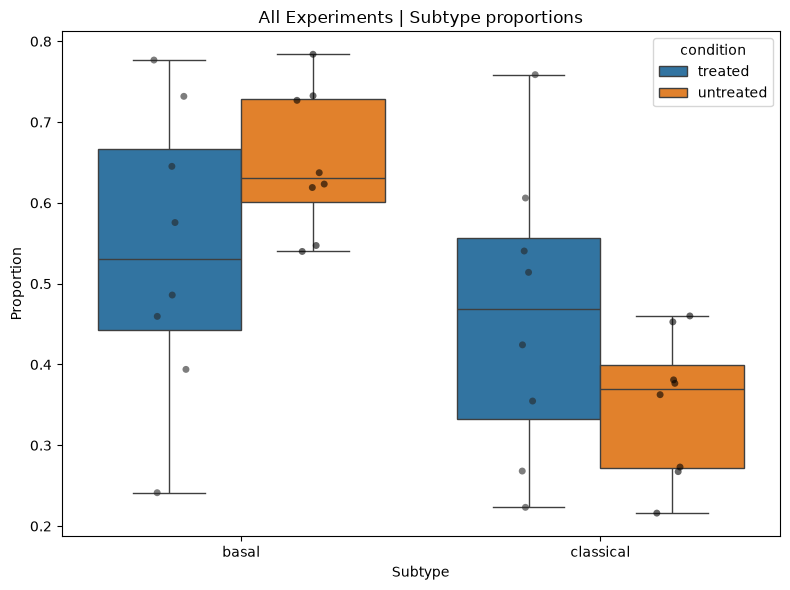

,experiment,sample_name,condition,labels,n_cells,proportion
0,batch2,batch2_1473_gem,treated,basal,796,0.485958
1,batch2,batch2_1473_gem,treated,classical,842,0.514042
2,batch2,batch2_1474_unt,untreated,basal,1014,0.619048
3,batch2,batch2_1474_unt,untreated,classical,624,0.380952
4,batch2,batch2_1485_unt,untreated,basal,1021,0.623321


In [7]:
from itertools import product

# =========================
# 2. ALL EXPERIMENTS
# =========================

treated = df[df["condition"] == "treated"]
untreated = df[df["condition"] == "untreated"]

plot_treatment_comparisons(
    treated=treated,
    untreated=untreated,
    cols=SEPARATING_MARKERS,
    title="All Experiments",
    fname=KDE_OUT / "all_experiments",
    figsize=(16, 12),
)

proportions = pd.read_csv(KDE_OUT / "all_experiments" / "subtype_proportions.csv")
display(proportions.head())

## 3. Each experiment

This loop filters the data to one experiment at a time, then separates treated and untreated cells. It saves the same five KDE comparisons and subtype proportion outputs in `KDE_OUT / "per_experiment" / exp`.


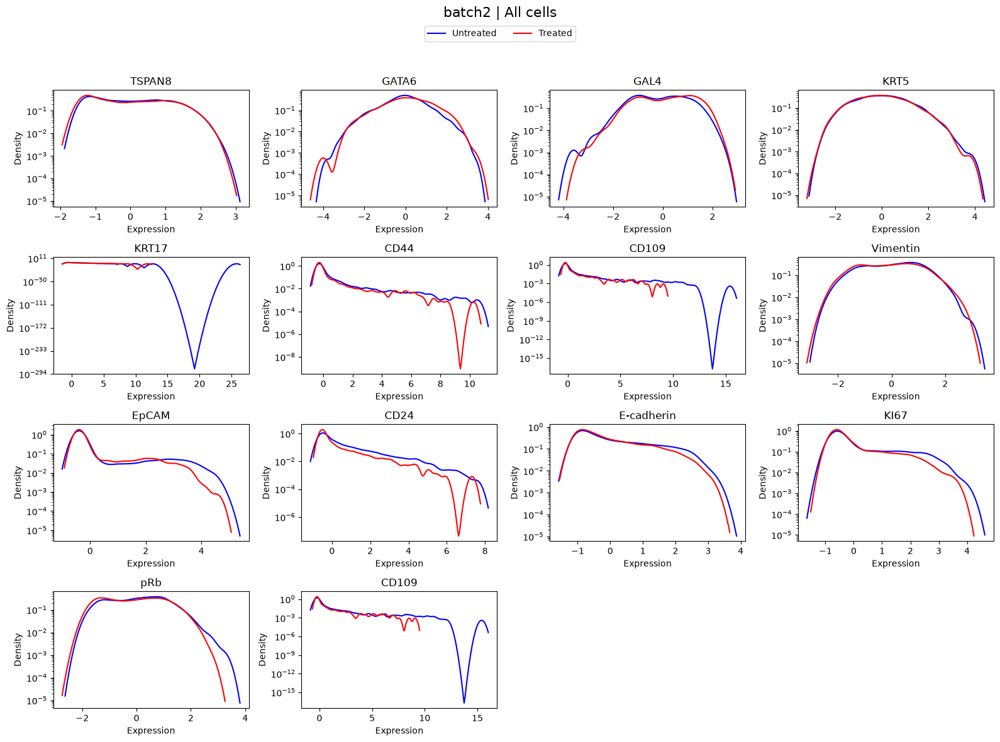

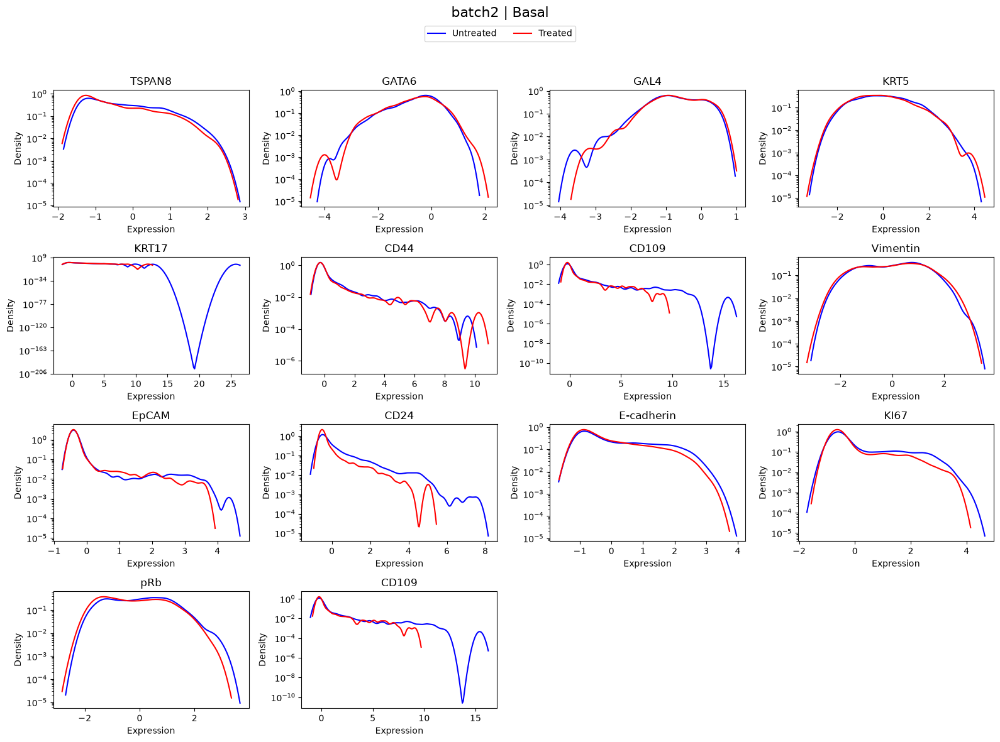

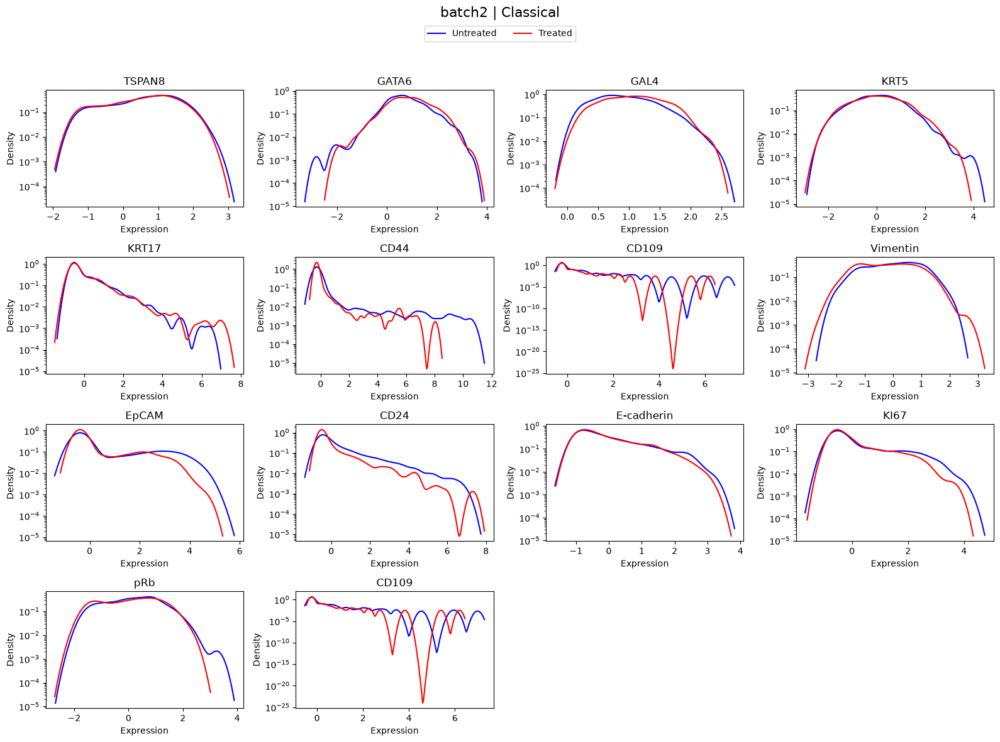

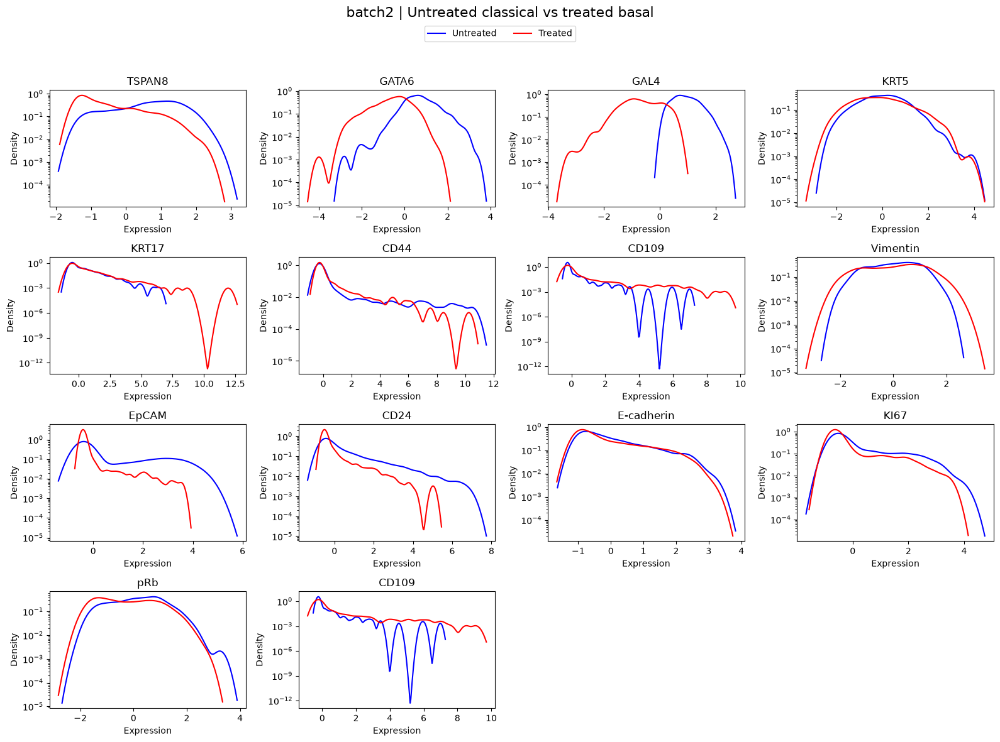

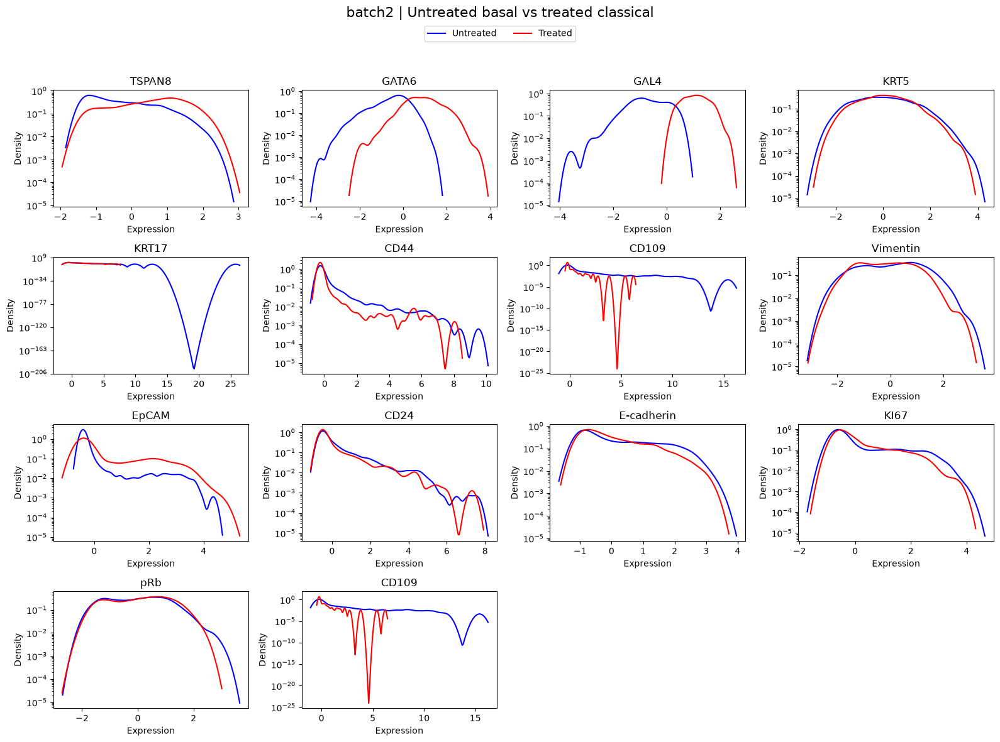

/Users/yishai/Desktop/epigenetics_field_theory/app/analysis/kde.py:208: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(


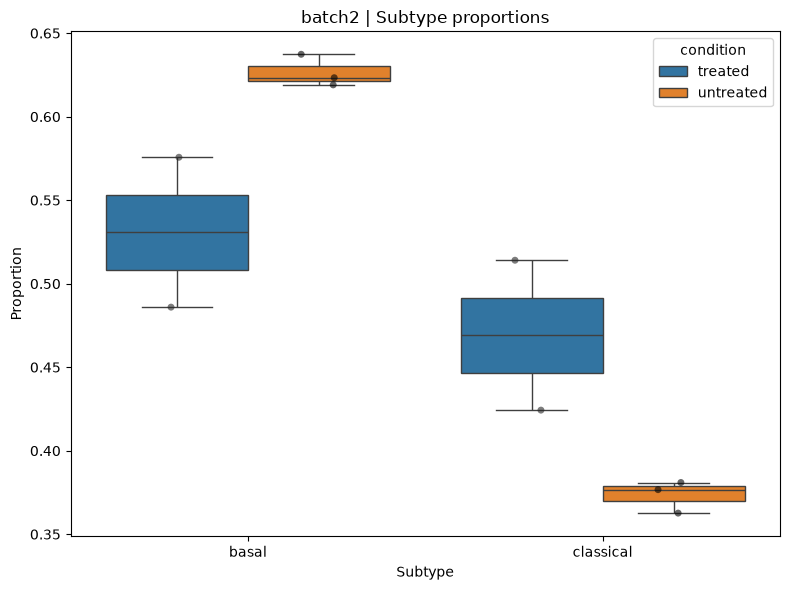

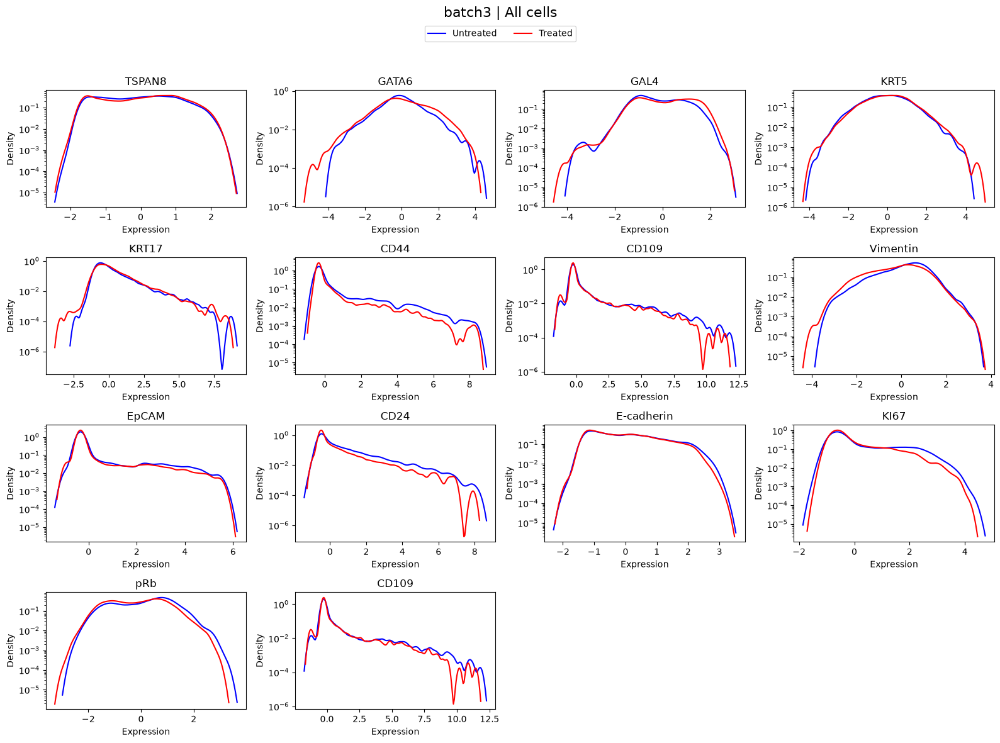

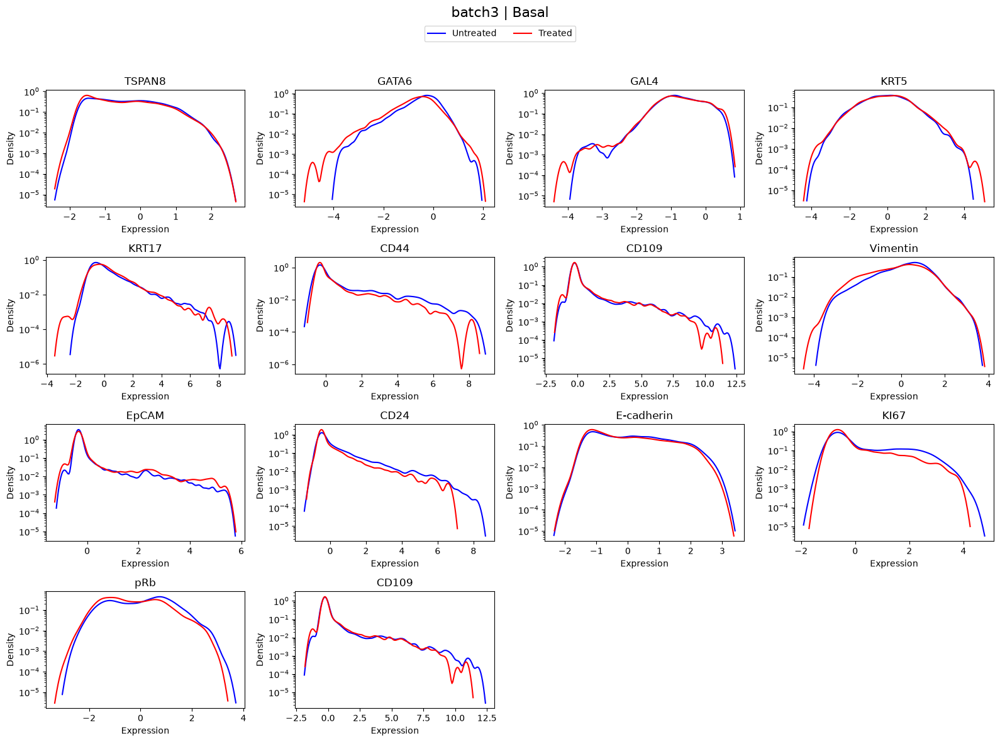

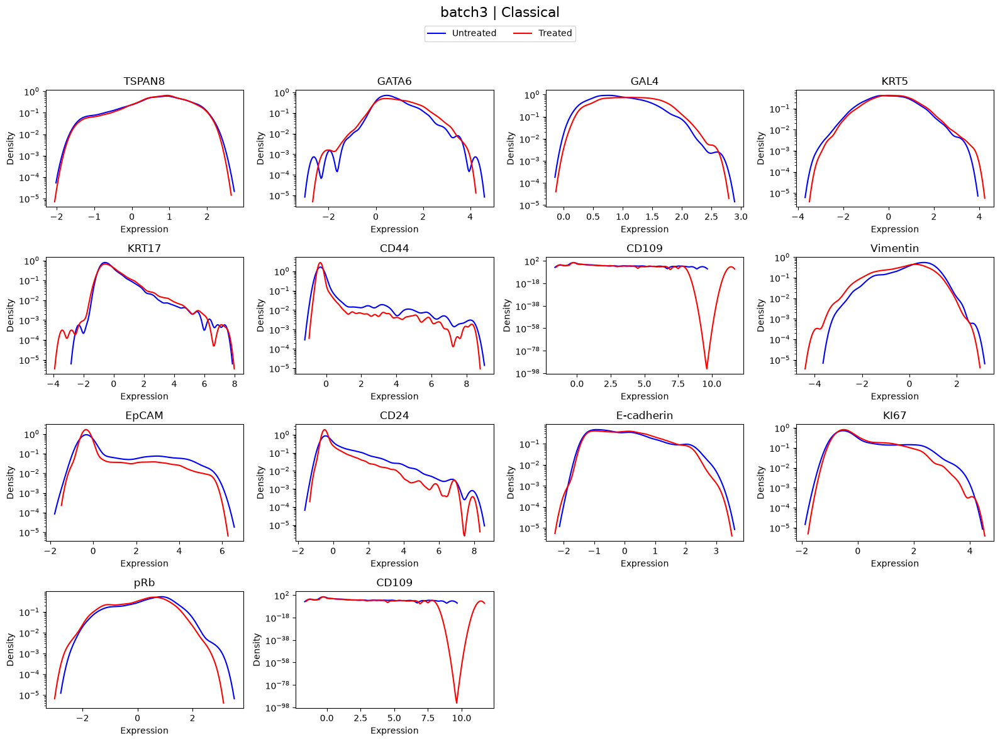

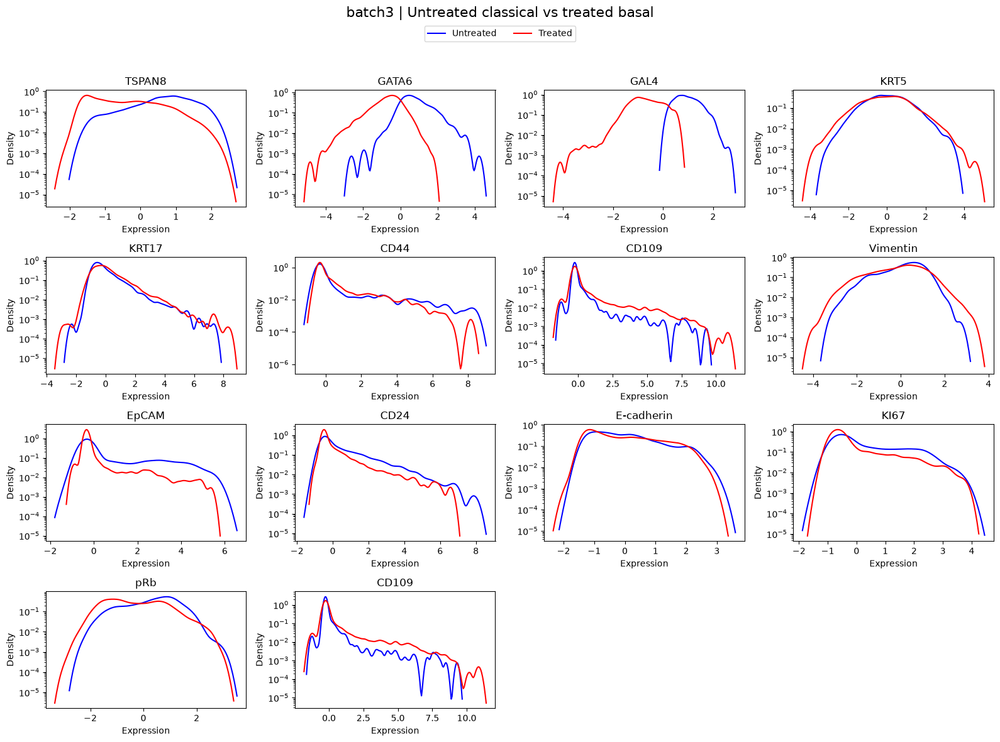

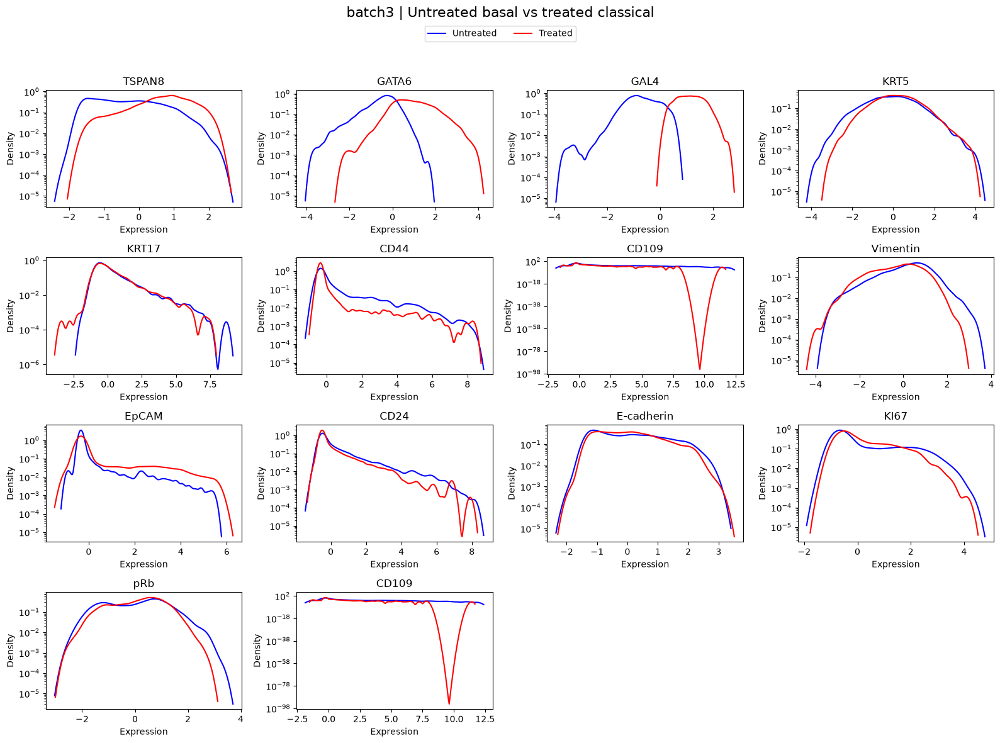

/Users/yishai/Desktop/epigenetics_field_theory/app/analysis/kde.py:208: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(


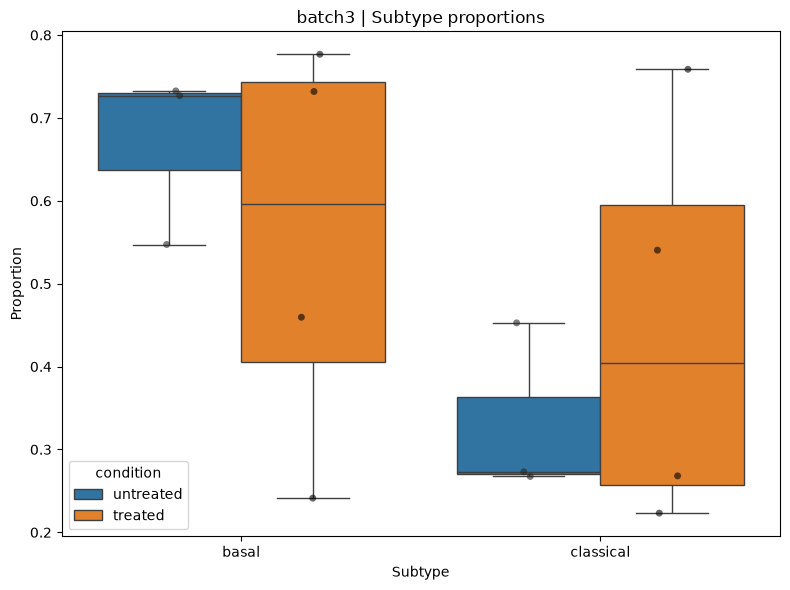

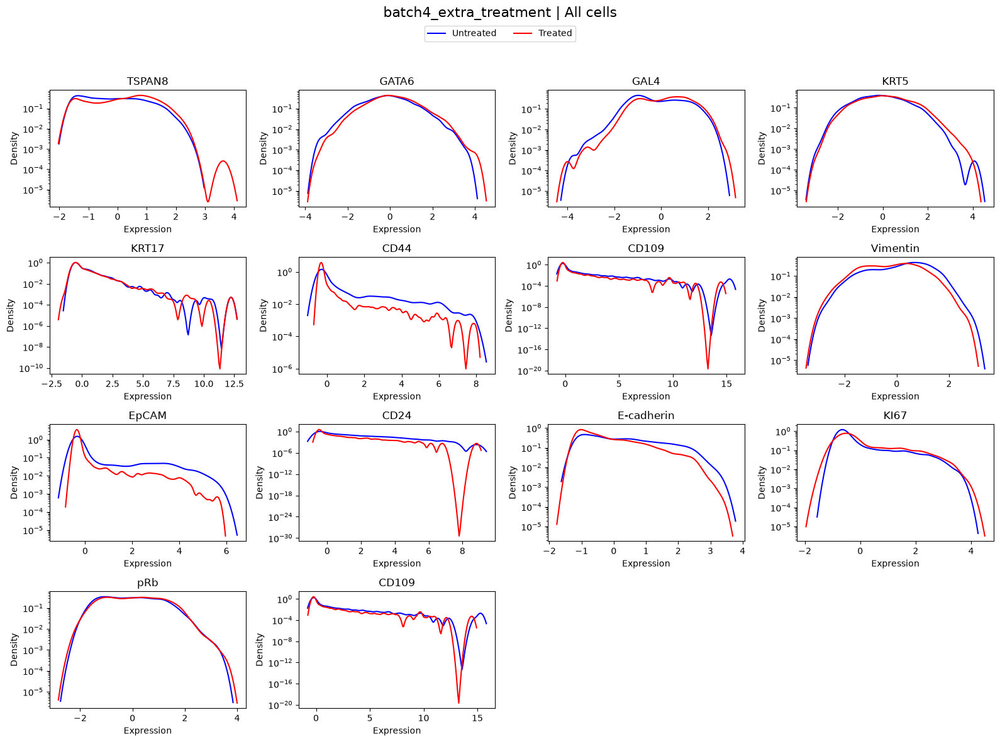

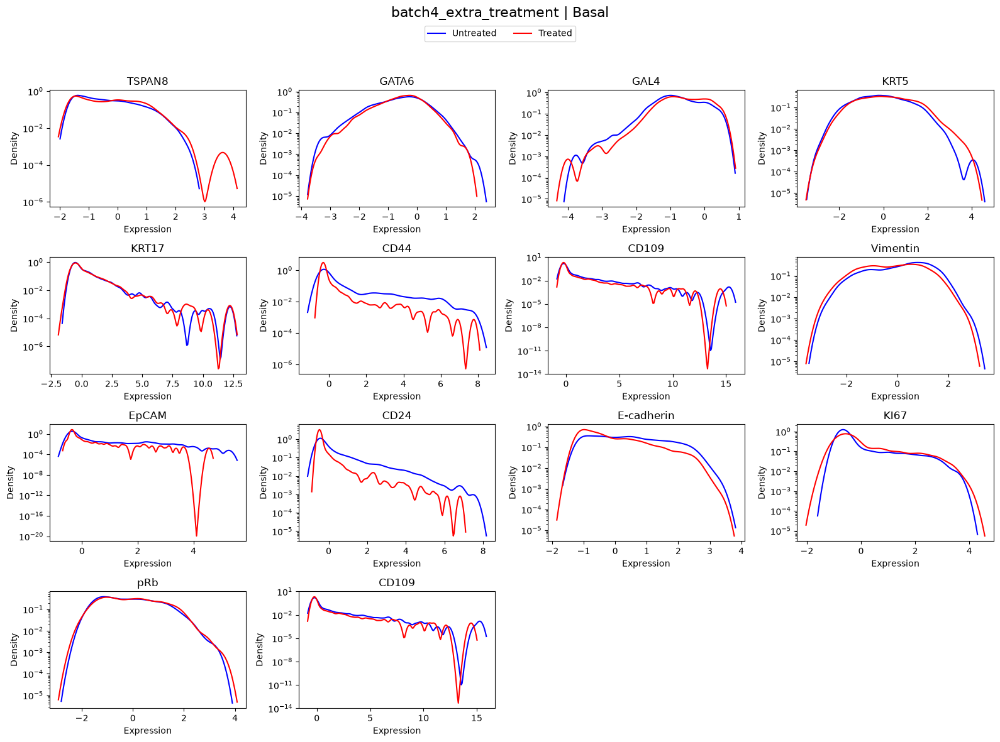

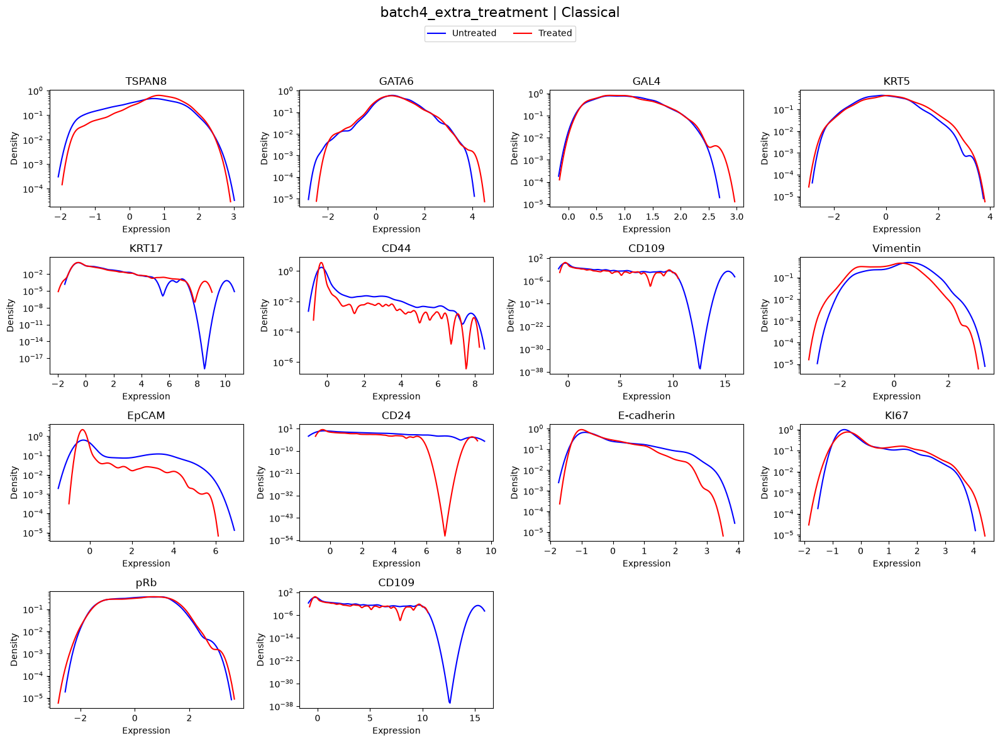

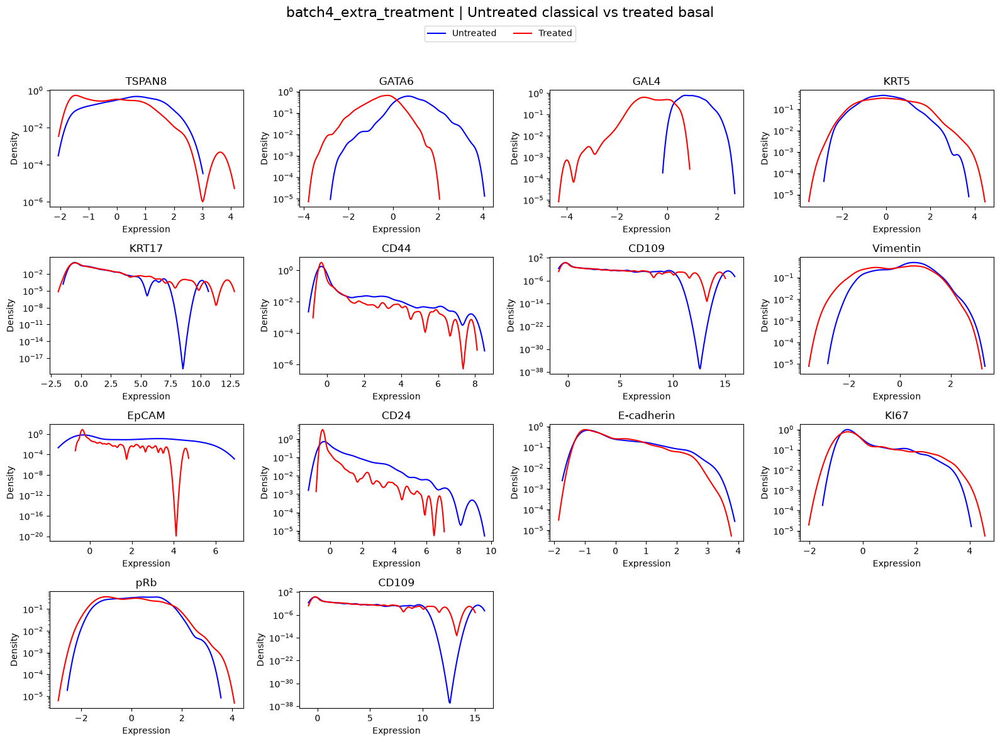

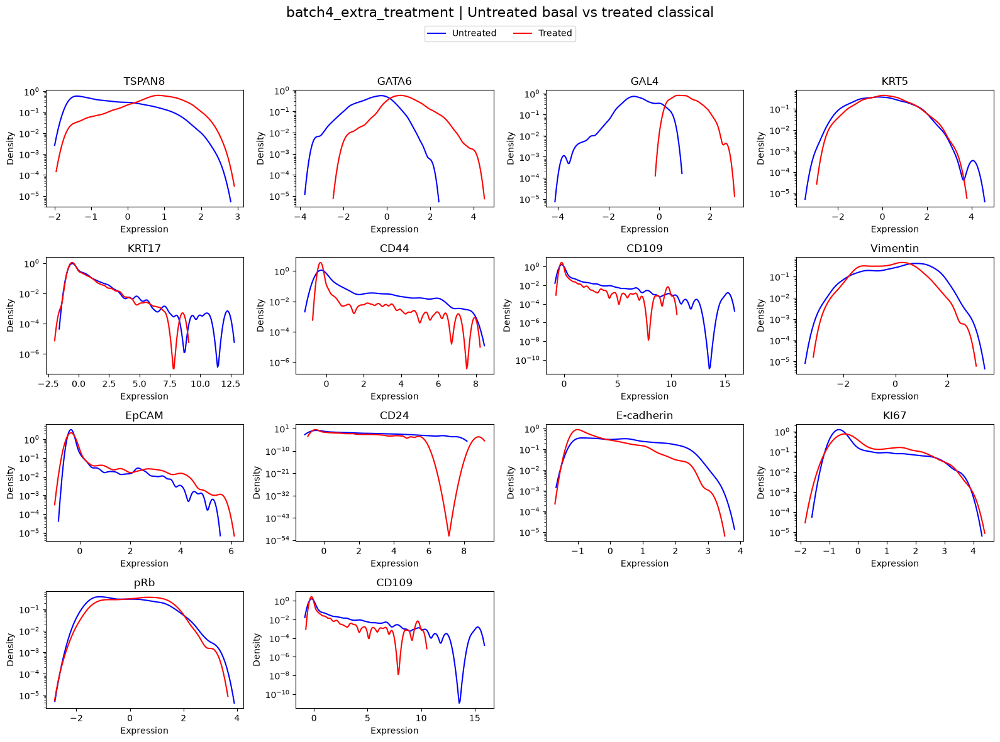

/Users/yishai/Desktop/epigenetics_field_theory/app/analysis/kde.py:208: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(


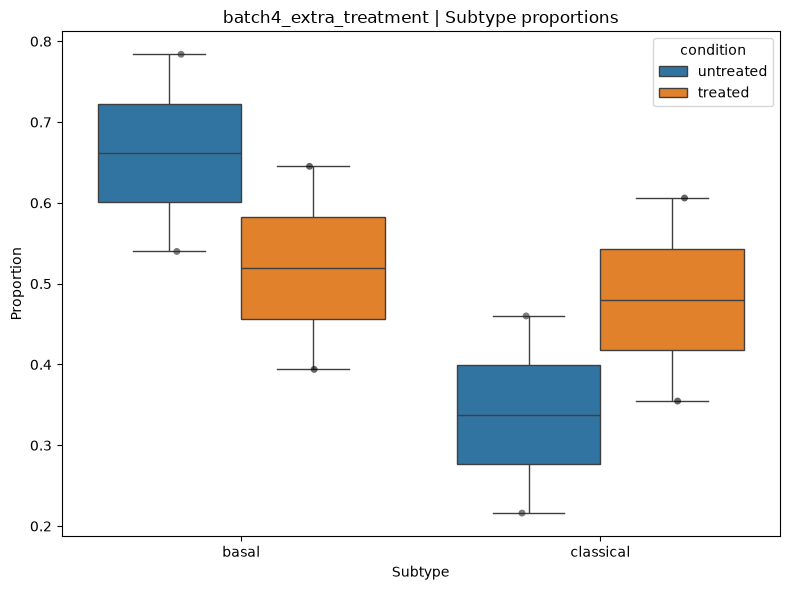

In [8]:
# =========================
# 3. EACH EXPERIMENT
# =========================

for exp in df["experiment"].unique():
    df_exp = df[df["experiment"] == exp]
    treated_exp = df_exp[df_exp["condition"] == "treated"]
    untreated_exp = df_exp[df_exp["condition"] == "untreated"]

    plot_treatment_comparisons(
        treated=treated_exp,
        untreated=untreated_exp,
        cols=SEPARATING_MARKERS,
        title=exp,
        fname=KDE_OUT / "per_experiment" / exp,
        figsize=(16, 12),
    )

## 4. Treated and untreated mouse pairs

Within each experiment, this loop takes the Cartesian product of treated and untreated sample names. It runs the same five comparisons for every pair and saves each result under `KDE_OUT / "mouse_pairs" / exp / treated_mouse_vs_untreated_mouse`.


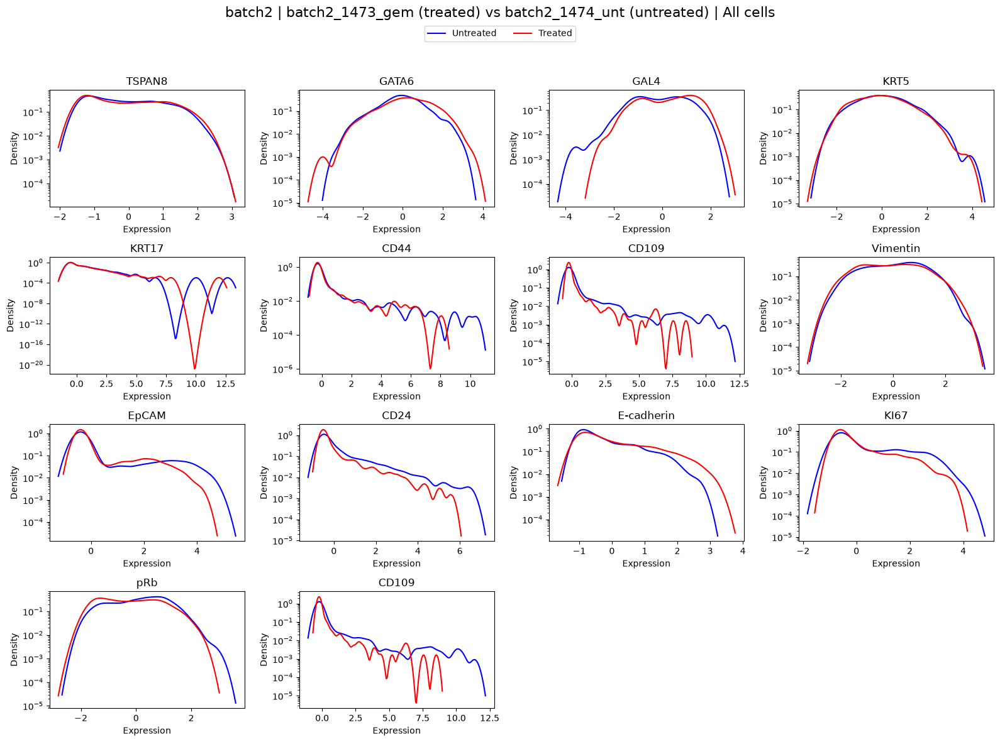

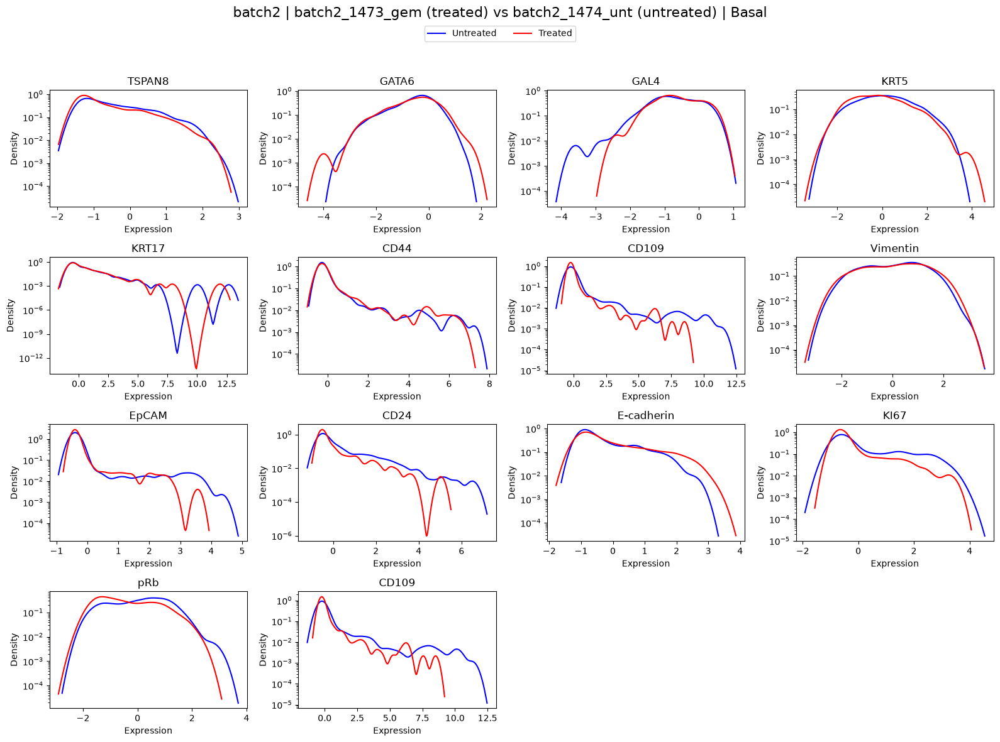

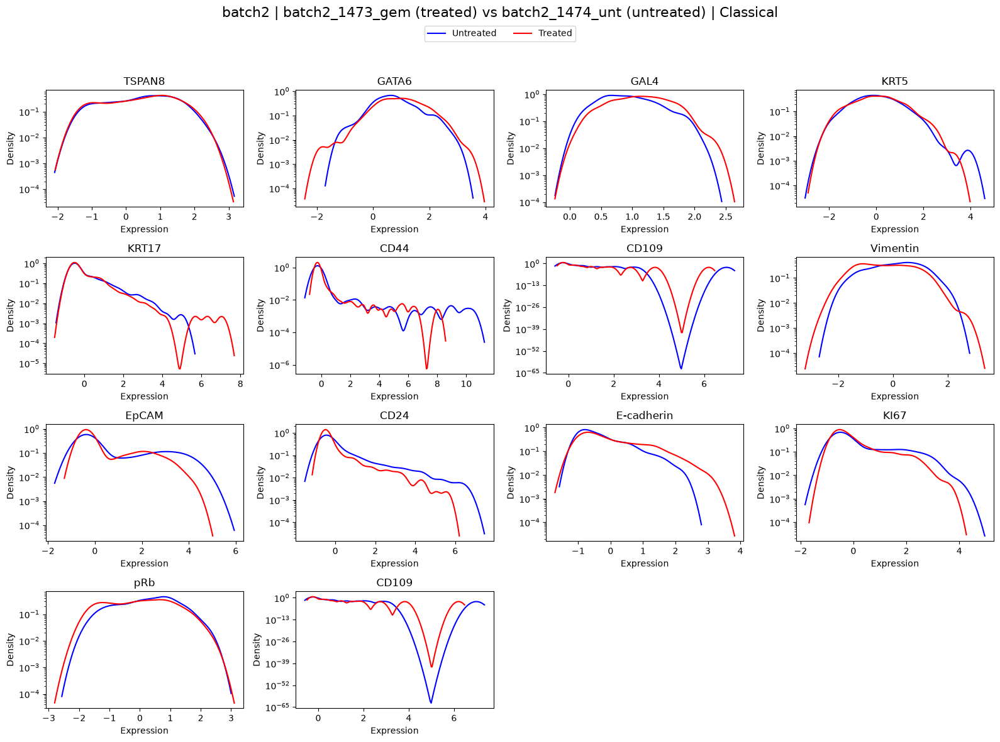

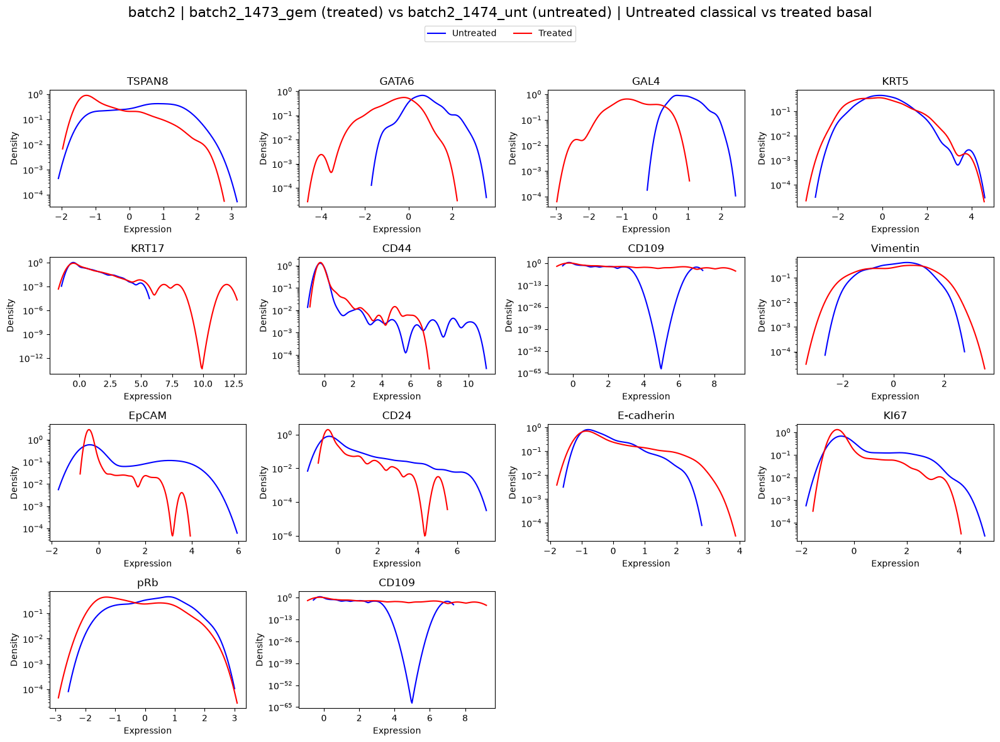

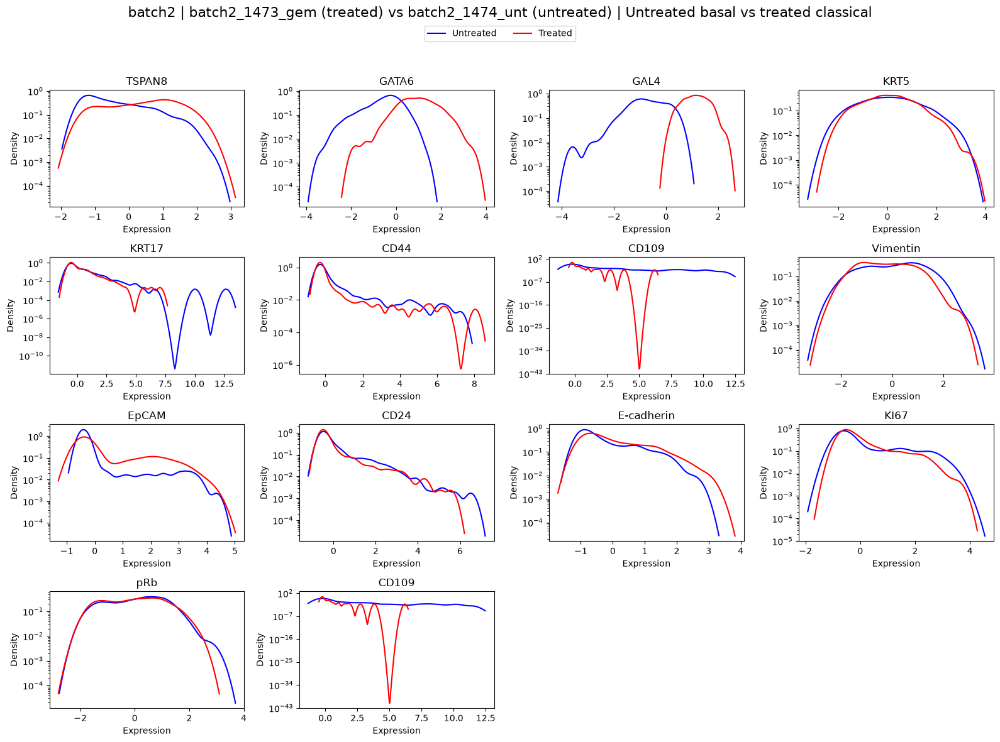

/Users/yishai/Desktop/epigenetics_field_theory/app/analysis/kde.py:208: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(


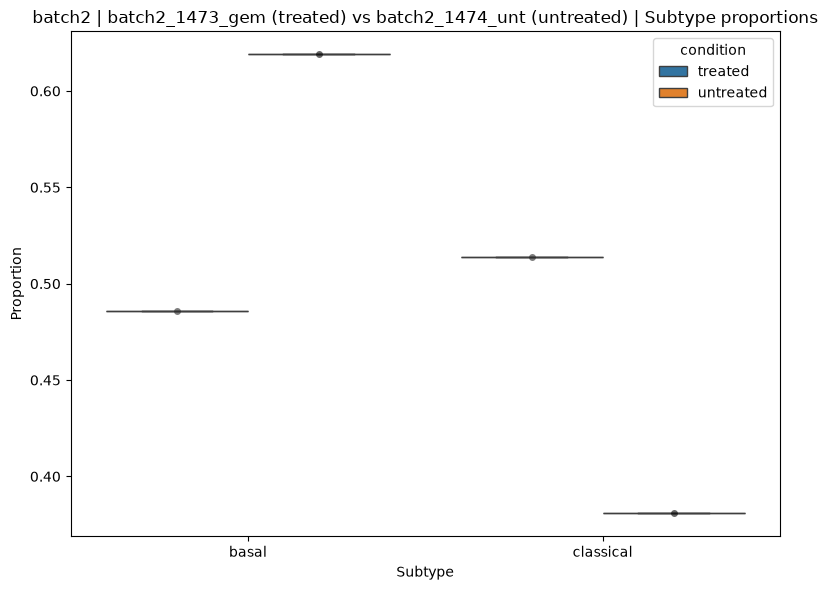

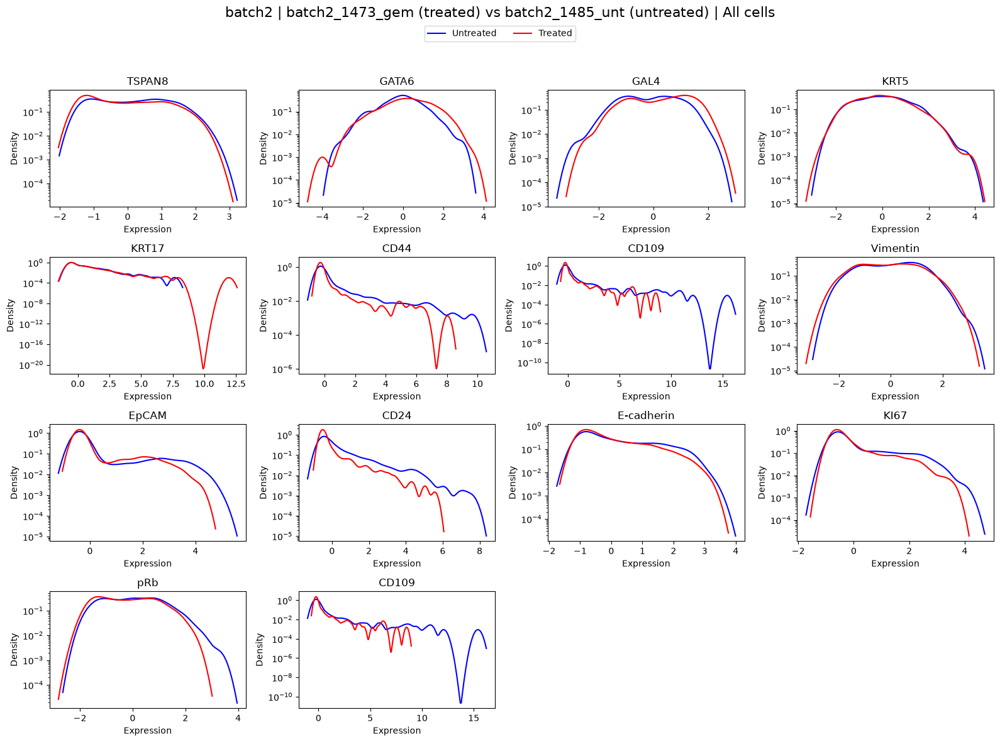

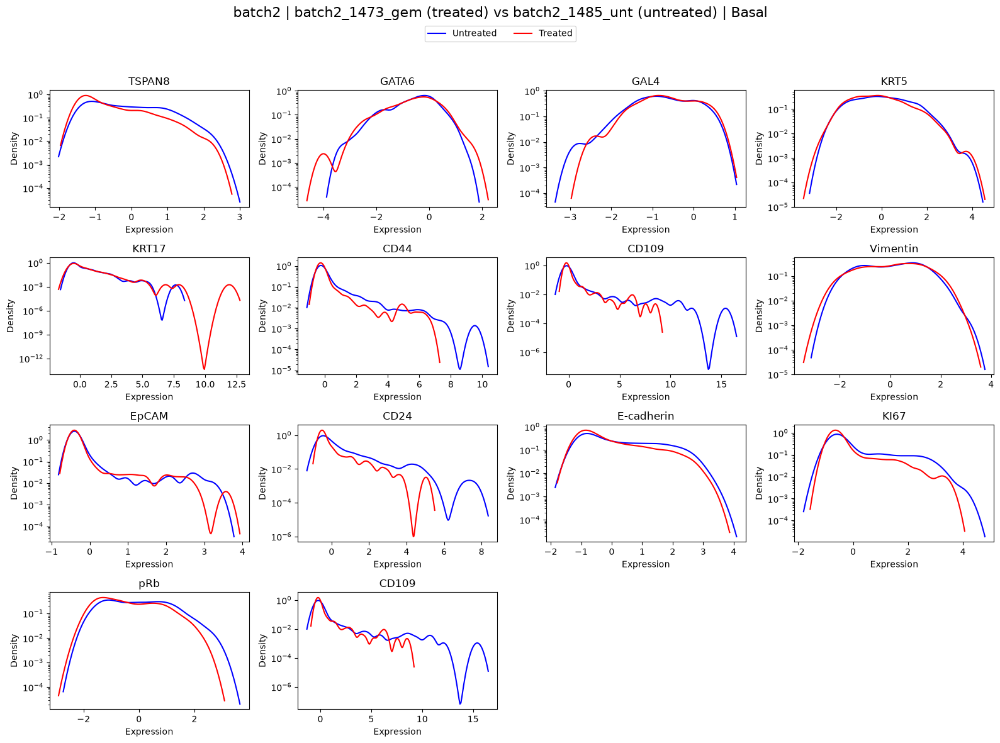

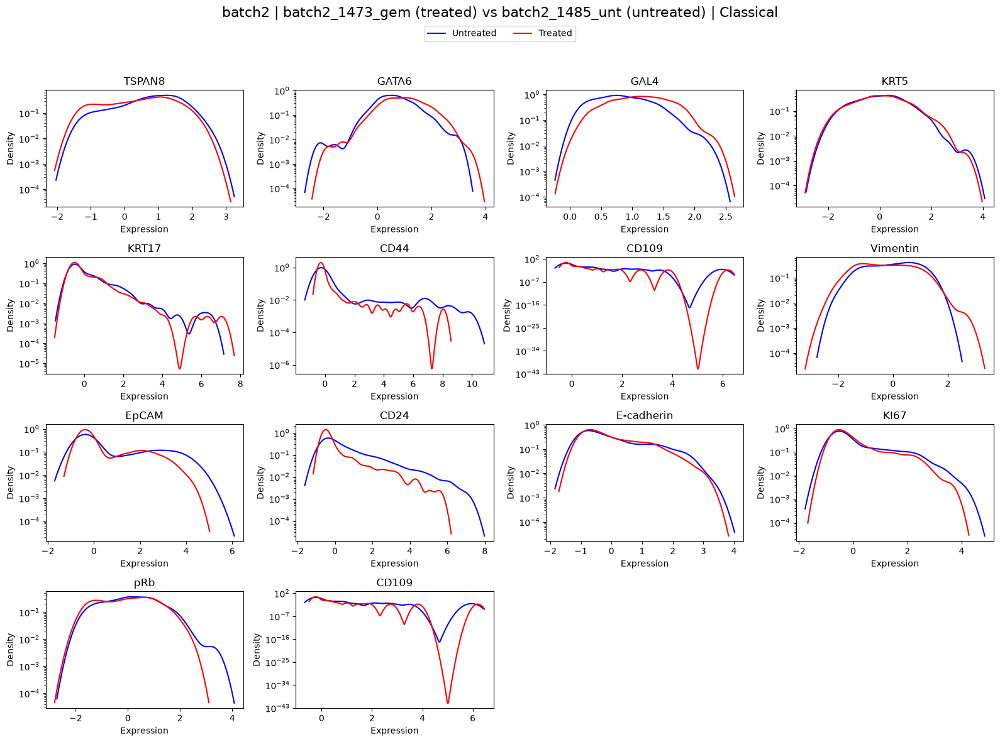

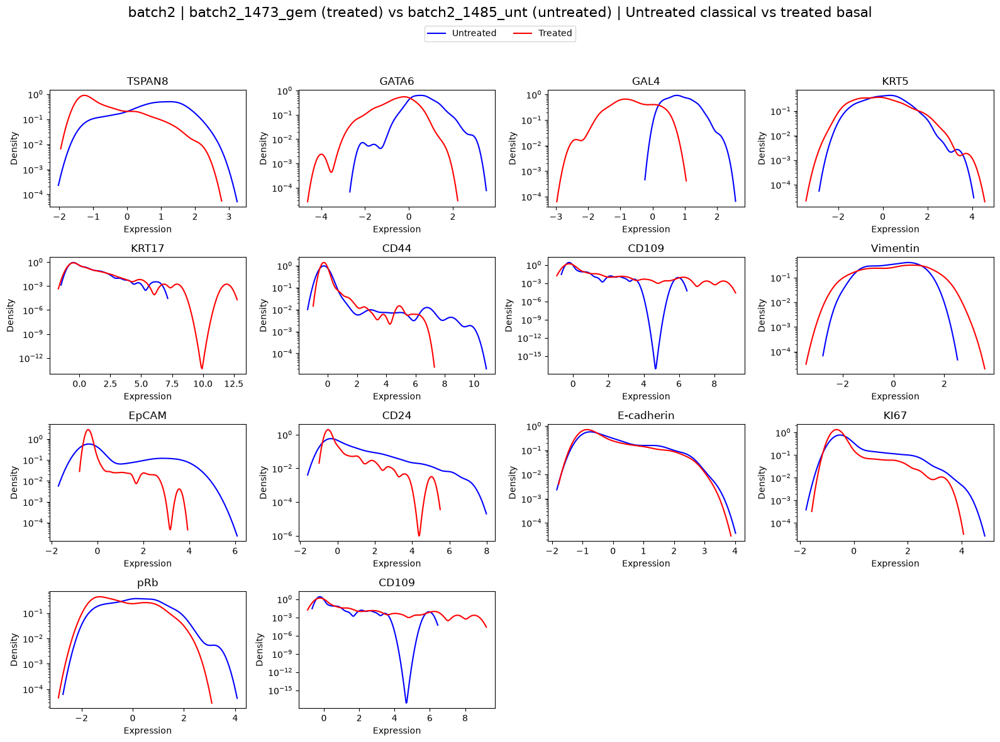

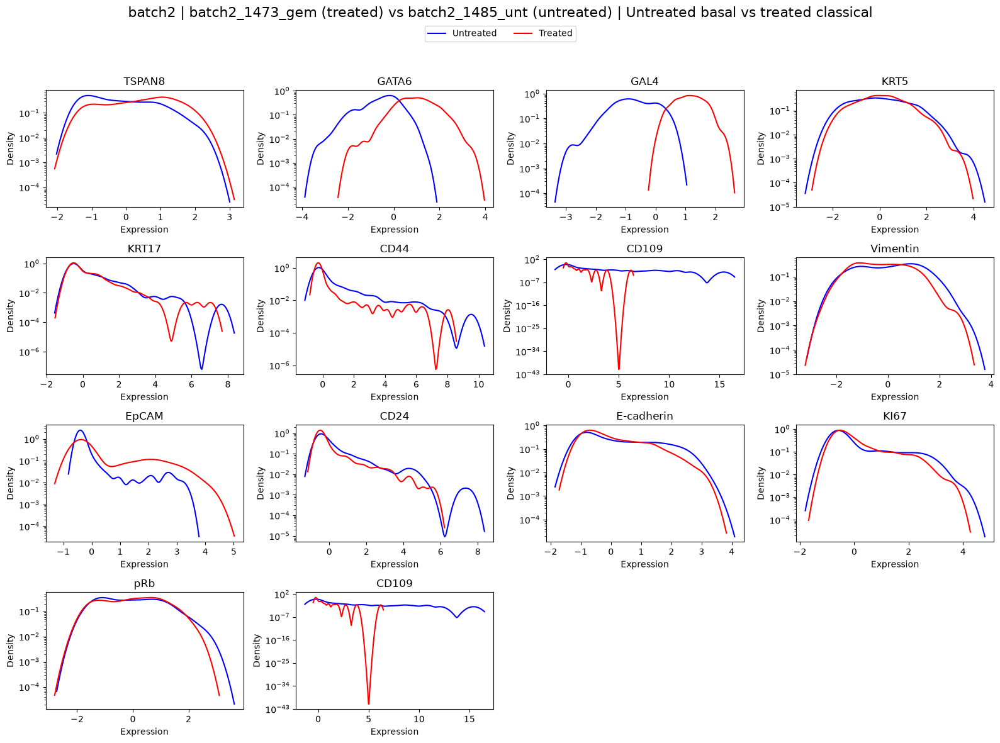

/Users/yishai/Desktop/epigenetics_field_theory/app/analysis/kde.py:208: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(


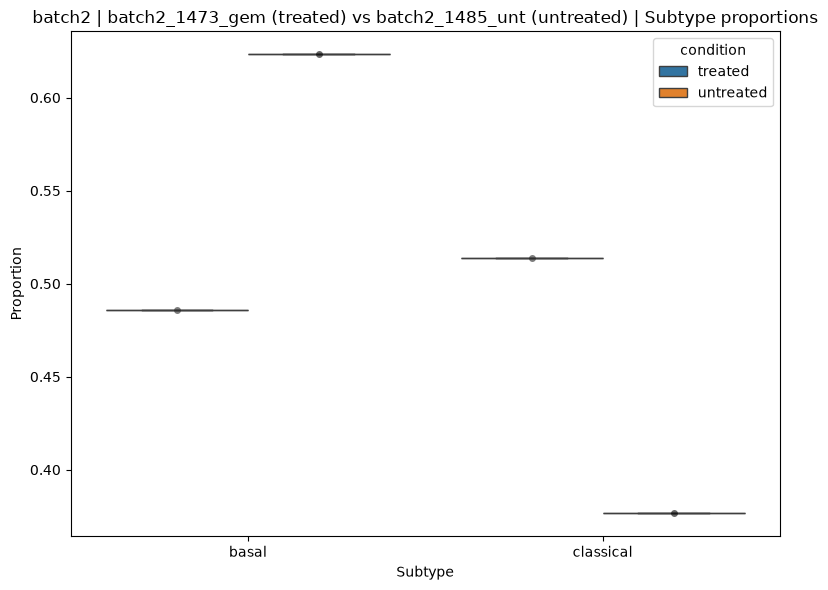

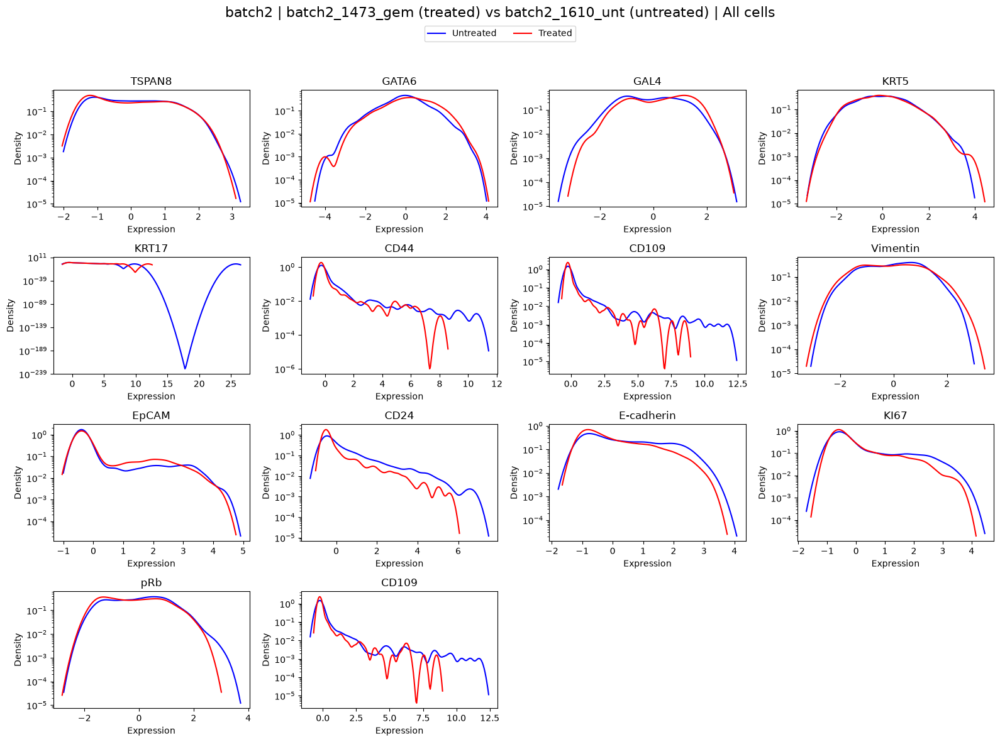

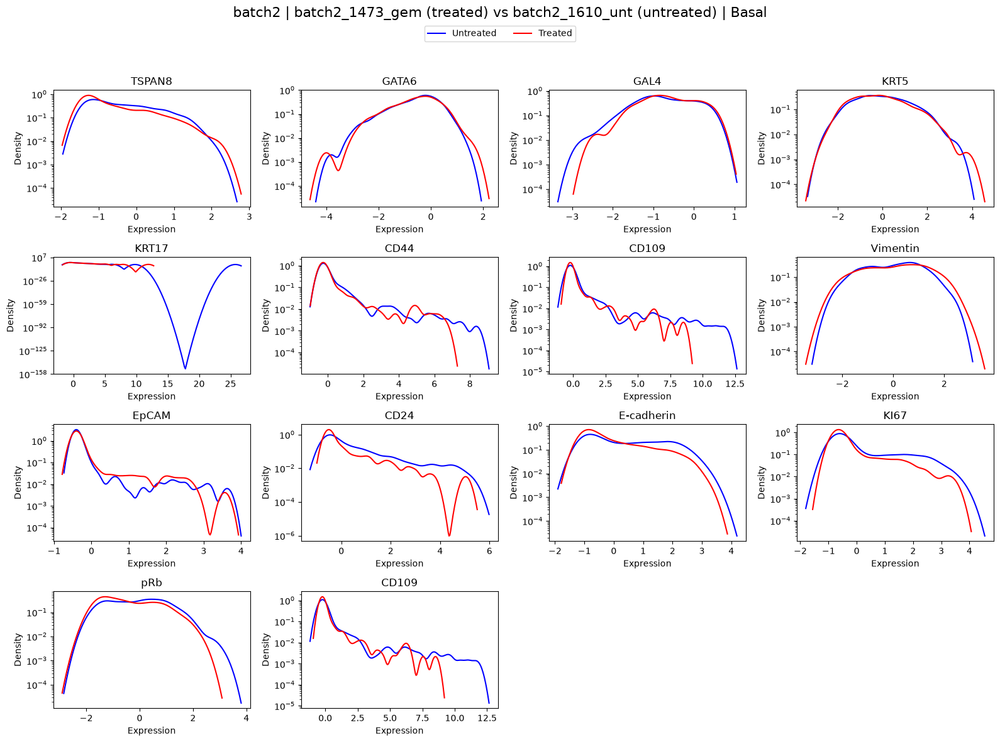

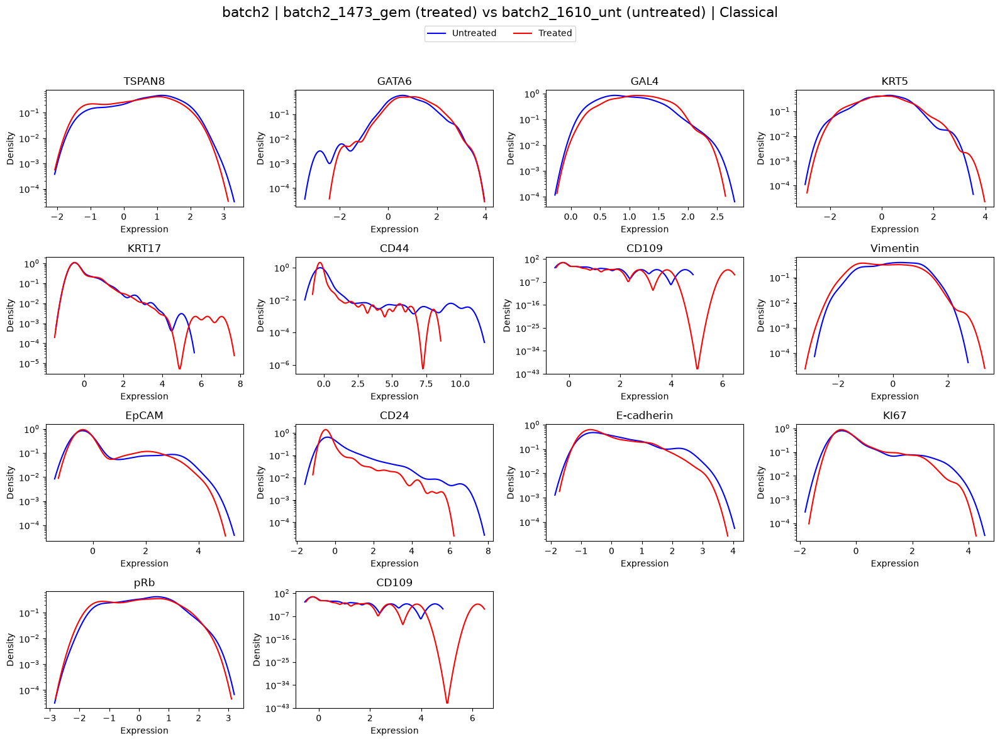

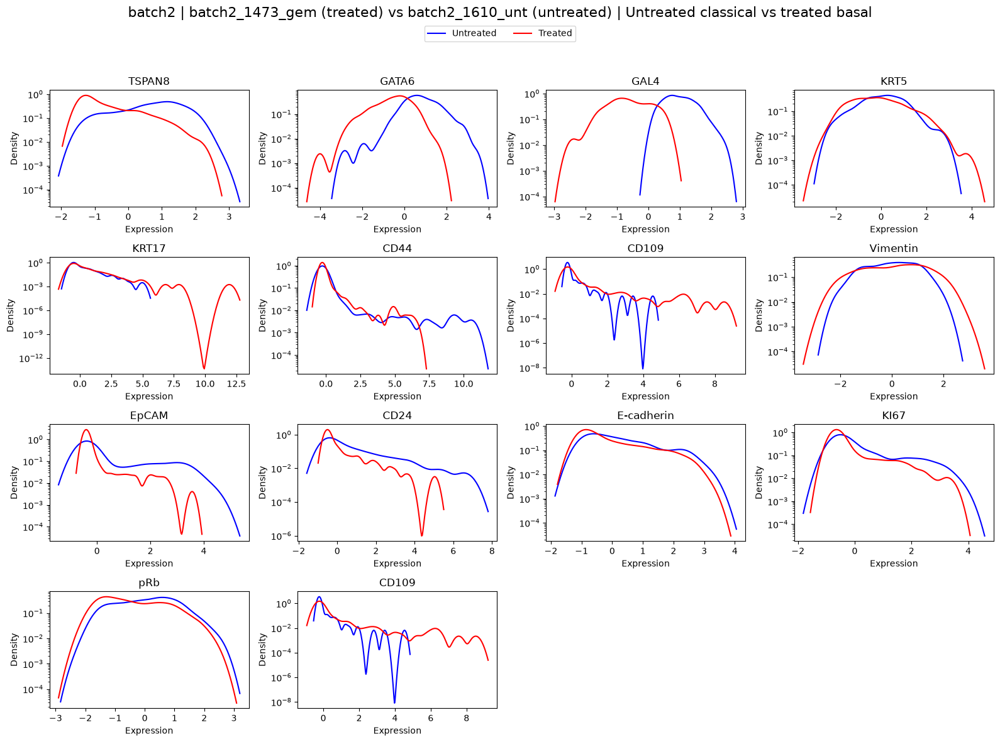

In [ ]:
# =========================
# 4. ALL MOUSE PAIRS WITHIN EACH EXPERIMENT
# =========================

for exp in df["experiment"].unique():
    df_exp = df[df["experiment"] == exp]
    treated_exp = df_exp[df_exp["condition"] == "treated"]
    untreated_exp = df_exp[df_exp["condition"] == "untreated"]

    treated_mice = treated_exp["sample_name"].unique()
    untreated_mice = untreated_exp["sample_name"].unique()

    for treated_mouse, untreated_mouse in product(treated_mice, untreated_mice):
        treated_mouse_df = treated_exp[treated_exp["sample_name"] == treated_mouse]
        untreated_mouse_df = untreated_exp[untreated_exp["sample_name"] == untreated_mouse]

        plot_treatment_comparisons(
            treated=treated_mouse_df,
            untreated=untreated_mouse_df,
            cols=SEPARATING_MARKERS,
            title=f"{exp} | {treated_mouse} (treated) vs {untreated_mouse} (untreated)",
            fname=KDE_OUT / "mouse_pairs" / exp / f"{treated_mouse}_vs_{untreated_mouse}",
            figsize=(16, 12),
        )